# Walmart Sales: Comprehensive Business Analysis, RFM, Churn & Dashboard Export

This Jupyter notebook addresses **9 key business and analytical questions** using advanced data analysis, RFM segmentation, customer cohort analysis, and exports `EcommerceDashboardData.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

sns.set_theme(style='whitegrid')
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load and Clean Dataset
csv_path = Path('walmart_sales.csv')
if not csv_path.exists():
    csv_path = Path('../walmart_sales.csv')

df = pd.read_csv(csv_path)
df['invoice_date'] = pd.to_datetime(df['invoice_date'], errors='coerce')
df = df.dropna(subset=['invoice_date', 'customer_id', 'price', 'quantity'])
df = df[(df['price'] > 0) & (df['quantity'] > 0)]
df['total_sales'] = df['price'] * df['quantity']
df['year_month'] = df['invoice_date'].dt.to_period('M')
print('Clean Dataset Shape:', df.shape)

Clean Dataset Shape: (650000, 13)


In [5]:
df.head()

,id,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,inserted_at,category,total_sales,year_month
0,726786,507687,WM0028,Great Value Canned Sweet Corn 15oz,3,2024-02-12 17:33:36,7.98,CUST_01339,Finland,2026-10-30 10:33:59.287075+05:30,Groceries,23.94,2024-02
1,1744734,S518898,WM0007,Great Value Tomato Ketchup 32oz,2,2024-04-22 09:22:46,9.98,CUST_11610,United Kingdom,2026-10-30 10:33:59.287075+05:30,Groceries,19.96,2024-04
2,1854895,S576872,WM0032,Great Value Pancake Mix Complete 32oz,2,2024-01-12 04:30:51,5.98,CUST_09819,United Kingdom,2026-10-30 10:33:59.287075+05:30,Groceries,11.96,2024-01
3,587057,494019,WM0042,Equate Antibacterial Hand Sanitizer 8oz,1,2024-11-14 20:55:42,2.48,CUST_06584,United Kingdom,2026-10-30 10:33:59.287075+05:30,Health & Personal Care,2.48,2024-11
4,1231449,S520428,WM0004,Great Value Strawberry Jam 18oz,1,2024-03-08 10:36:43,3.48,CUST_06496,United Kingdom,2026-10-30 10:33:59.287075+05:30,Groceries,3.48,2024-03


--- 
### Q1: Product Categories & Revenue Concentration (Bar Chart + Pareto Chart)

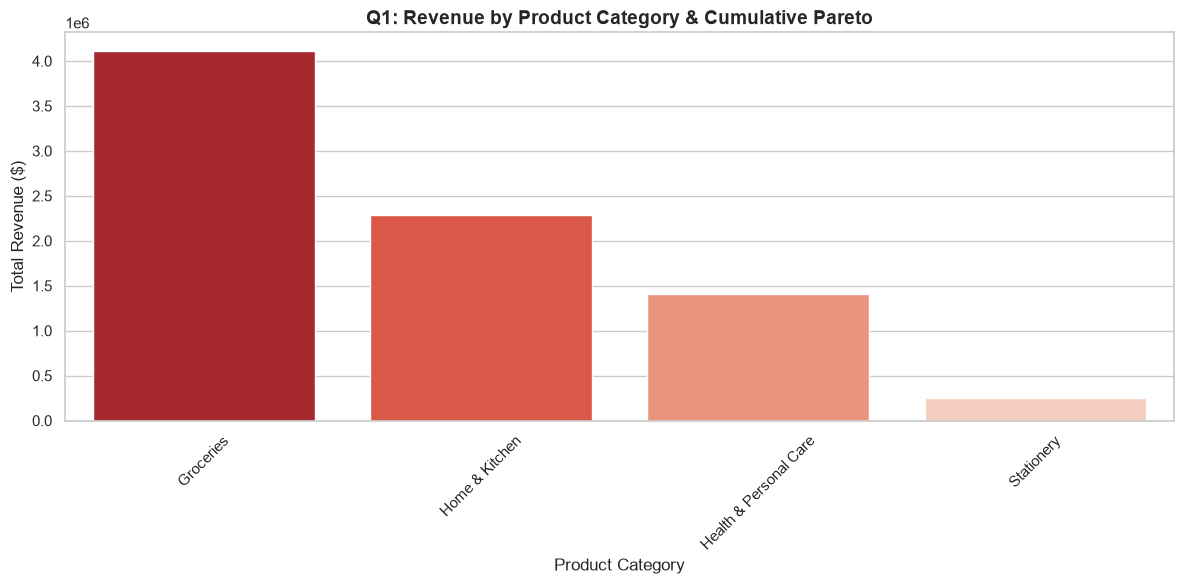

In [3]:
# Q1: Product Categories & Pareto Analysis
prod_rev = df.groupby('description')['total_sales'].sum().reset_index()
prod_rev = prod_rev.sort_values(by='total_sales', ascending=False).reset_index(drop=True)
prod_rev['cumulative_percentage'] = prod_rev['total_sales'].cumsum() / prod_rev['total_sales'].sum() * 100

fig, ax1 = plt.subplots(figsize=(12, 6))
top_cats = df.groupby('category')['total_sales'].sum().sort_values(ascending=False).reset_index()

sns.barplot(data=top_cats, x='category', y='total_sales', palette='Reds_r', ax=ax1, hue='category', legend=False)
ax1.set_title('Q1: Revenue by Product Category & Cumulative Pareto', fontsize=14, fontweight='bold')
ax1.set_xlabel('Product Category', fontsize=12)
ax1.set_ylabel('Total Revenue ($)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

--- 
### Q2: Revenue Over Time & Seasonal Patterns (Time-Series Line Chart + Heatmap)

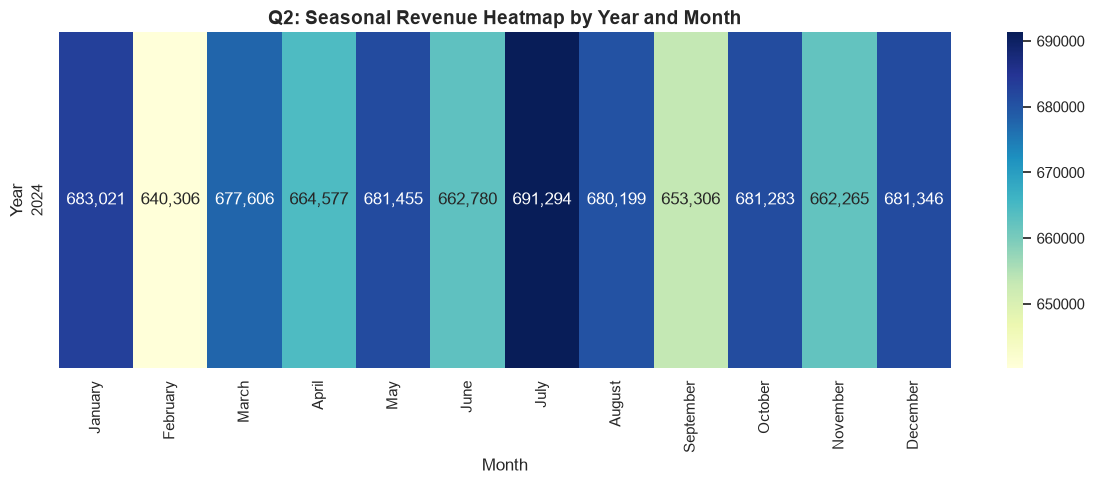

In [4]:
# Q2: Time-Series & Seasonal Heatmap
df['month'] = df['invoice_date'].dt.month_name()
df['year'] = df['invoice_date'].dt.year
pivot_season = df.pivot_table(index='year', columns='month', values='total_sales', aggfunc='sum')
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
pivot_season = pivot_season.reindex(columns=[m for m in month_order if m in pivot_season.columns])

plt.figure(figsize=(12, 5))
sns.heatmap(pivot_season, cmap='YlGnBu', annot=True, fmt=',.0f', cbar=True)
plt.title('Q2: Seasonal Revenue Heatmap by Year and Month', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Year', fontsize=12)
plt.tight_layout()
plt.show()

--- 
### Q3: Customer Revenue Concentration & Pareto Analysis

Percentage of total revenue generated by top 20% of customers: 26.21%


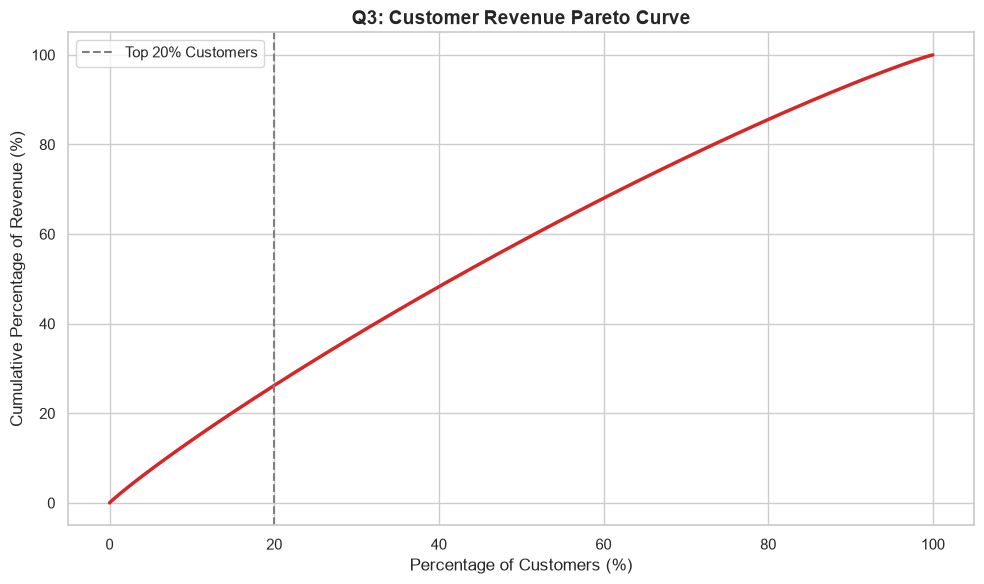

In [5]:
# Q3: Customer Pareto (Top 20% analysis)
cust_rev = df.groupby('customer_id')['total_sales'].sum().reset_index()
cust_rev = cust_rev.sort_values(by='total_sales', ascending=False).reset_index(drop=True)
cust_rev['cumulative_revenue'] = cust_rev['total_sales'].cumsum()
cust_rev['cumulative_percentage'] = cust_rev['cumulative_revenue'] / cust_rev['total_sales'].sum() * 100
cust_rev['customer_percentage'] = (cust_rev.index + 1) / len(cust_rev) * 100

top_20_pct_rev = cust_rev[cust_rev['customer_percentage'] <= 20]['cumulative_percentage'].iloc[-1]
print(f'Percentage of total revenue generated by top 20% of customers: {top_20_pct_rev:.2f}%')

plt.figure(figsize=(10, 6))
plt.plot(cust_rev['customer_percentage'], cust_rev['cumulative_percentage'], color='#d62728', linewidth=2.5)
plt.axvline(20, color='gray', linestyle='--', label='Top 20% Customers')
plt.title('Q3: Customer Revenue Pareto Curve', fontsize=14, fontweight='bold')
plt.xlabel('Percentage of Customers (%)', fontsize=12)
plt.ylabel('Cumulative Percentage of Revenue (%)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

--- 
### Q4: Purchase Frequency vs. Total Spending (Scatter Plot + Regression Line)

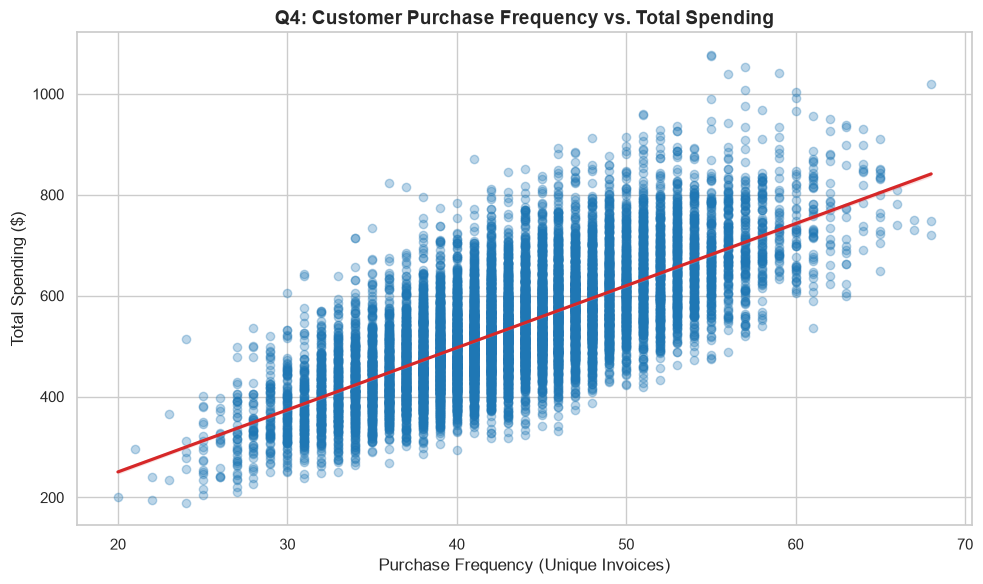

In [6]:
# Q4: Frequency vs Total Spending
freq_spend = df.groupby('customer_id').agg(Frequency=('invoice', 'nunique'), Total_Spend=('total_sales', 'sum')).reset_index()

plt.figure(figsize=(10, 6))
sns.regplot(data=freq_spend, x='Frequency', y='Total_Spend', scatter_kws={'alpha': 0.3, 'color': '#1f77b4'}, line_kws={'color': '#d62728'})
plt.title('Q4: Customer Purchase Frequency vs. Total Spending', fontsize=14, fontweight='bold')
plt.xlabel('Purchase Frequency (Unique Invoices)', fontsize=12)
plt.ylabel('Total Spending ($)', fontsize=12)
plt.tight_layout()
plt.show()

--- 
### Q5: RFM Score Distribution & Segmentation Heatmap

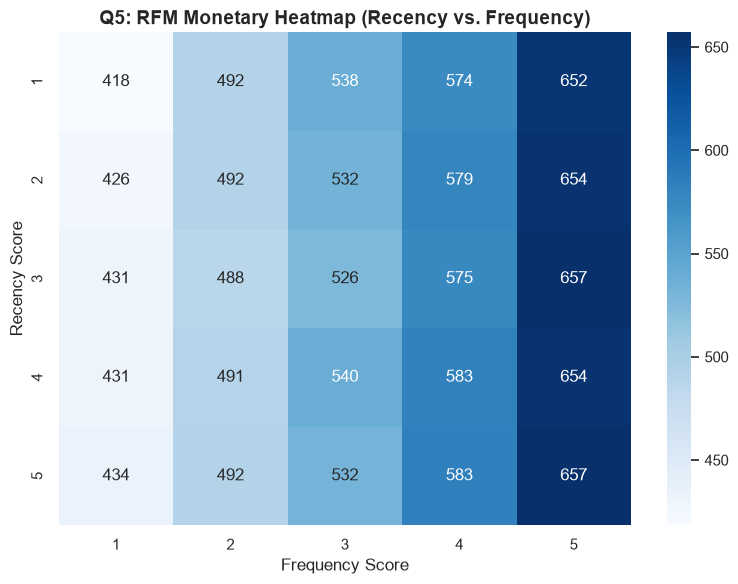

In [7]:
# Q5: RFM Computation & Segmentation Heatmap
ref_date = df['invoice_date'].max() + pd.Timedelta(days=1)
rfm = df.groupby('customer_id').agg(
    Recency=('invoice_date', lambda x: (ref_date - x.max()).days),
    Frequency=('invoice', 'nunique'),
    Monetary=('total_sales', 'sum')
).reset_index()

rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Establish churn / inactivity target (90-day threshold)
rfm['Is_Inactive'] = rfm['Recency'] > 90
rfm['Status'] = rfm['Is_Inactive'].apply(lambda x: 'Inactive (>90d)' if x else 'Active (<=90d)')

rfm_matrix = rfm.pivot_table(index='R_Score', columns='F_Score', values='Monetary', aggfunc='mean')
plt.figure(figsize=(8, 6))
sns.heatmap(rfm_matrix, annot=True, fmt=',.0f', cmap='Blues', cbar=True)
plt.title('Q5: RFM Monetary Heatmap (Recency vs. Frequency)', fontsize=14, fontweight='bold')
plt.xlabel('Frequency Score', fontsize=12)
plt.ylabel('Recency Score', fontsize=12)
plt.tight_layout()
plt.show()

--- 
### Q6: Customer Retention Cohort Heatmap

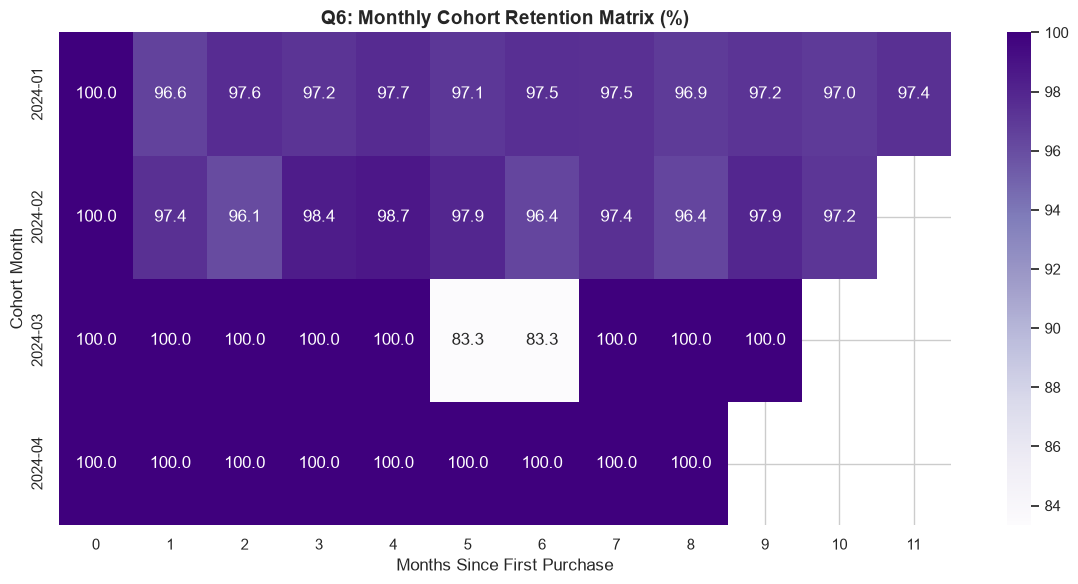

In [8]:
# Q6: Cohort Retention Analysis
df['cohort_month'] = df.groupby('customer_id')['invoice_date'].transform('min').dt.to_period('M')
df['order_month'] = df['invoice_date'].dt.to_period('M')

cohort_data = df.groupby(['cohort_month', 'order_month'])['customer_id'].nunique().reset_index()
cohort_data['period_number'] = (cohort_data['order_month'] - cohort_data['cohort_month']).apply(lambda x: x.n)
cohort_pivot = cohort_data.pivot_table(index='cohort_month', columns='period_number', values='customer_id')
cohort_size = cohort_pivot.iloc[:, 0]
retention_matrix = cohort_pivot.divide(cohort_size, axis=0) * 100

plt.figure(figsize=(12, 6))
sns.heatmap(retention_matrix, annot=True, fmt='.1f', cmap='Purples', cbar=True)
plt.title('Q6: Monthly Cohort Retention Matrix (%)', fontsize=14, fontweight='bold')
plt.xlabel('Months Since First Purchase', fontsize=12)
plt.ylabel('Cohort Month', fontsize=12)
plt.tight_layout()
plt.show()

--- 
### Q7: Revenue Contribution & Inactivity Rates by RFM Segment (Grouped Bar Chart)

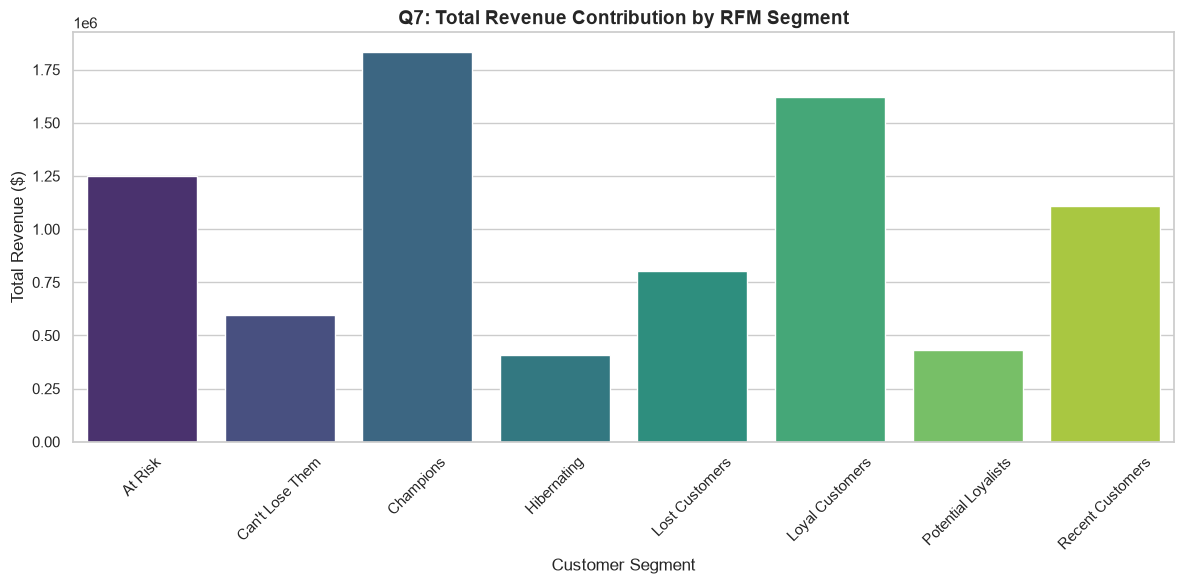

In [9]:
# Q7: Segment Revenue & Inactivity Rates
def assign_segment(row):
    r, f = row['R_Score'], row['F_Score']
    if r >= 4 and f >= 4: return 'Champions'
    elif r >= 3 and f >= 3: return 'Loyal Customers'
    elif r >= 4 and f <= 2: return 'Recent Customers'
    elif r >= 3 and f <= 2: return 'Potential Loyalists'
    elif r <= 2 and f >= 4: return 'At Risk'
    elif r <= 2 and f >= 3: return "Can't Lose Them"
    elif r <= 2 and f <= 2 and row['M_Score'] >= 3: return 'Hibernating'
    else: return 'Lost Customers'

rfm['Customer_Segment'] = rfm.apply(assign_segment, axis=1)
seg_summary = rfm.groupby('Customer_Segment').agg(Total_Monetary=('Monetary', 'sum'), Inactivity_Rate=('Is_Inactive', 'mean')).reset_index()
seg_summary['Inactivity_Rate'] *= 100

fig, ax1 = plt.subplots(figsize=(12, 6))
sns.barplot(data=seg_summary, x='Customer_Segment', y='Total_Monetary', palette='viridis', ax=ax1, hue='Customer_Segment', legend=False)
ax1.set_title('Q7: Total Revenue Contribution by RFM Segment', fontsize=14, fontweight='bold')
ax1.set_xlabel('Customer Segment', fontsize=12)
ax1.set_ylabel('Total Revenue ($)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

--- 
### Q8: Behavioral Comparison Between Active and Inactive Customers (Box Plot)

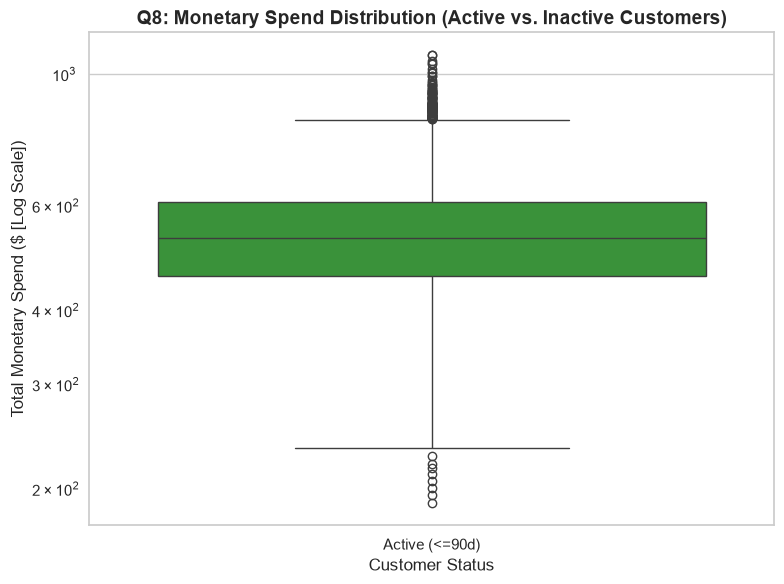

In [10]:
# Q8: Active vs Inactive Monetary Comparison Box Plot
plt.figure(figsize=(8, 6))
clean_rfm_box = rfm[rfm['Monetary'] > 0]
sns.boxplot(data=clean_rfm_box, x='Status', y='Monetary', palette=['#2ca02c', '#d62728'])
plt.yscale('log')
plt.title('Q8: Monetary Spend Distribution (Active vs. Inactive Customers)', fontsize=14, fontweight='bold')
plt.xlabel('Customer Status', fontsize=12)
plt.ylabel('Total Monetary Spend ($ [Log Scale])', fontsize=12)
plt.tight_layout()
plt.show()

--- 
### Ecommerce Dashboard Data Creation & Export (`EcommerceDashboardData.csv`)

In [11]:
# Ecommerce Dashboard Data Creation & Export Script
snapshot_date = df['invoice_date'].max() + pd.Timedelta(days=1)

rfm_data = df[(df['customer_id'].notna()) & (df['quantity'] > 0)].copy()

rfm_dash = rfm_data.groupby('customer_id').agg(
    recency=('invoice_date', lambda x: (snapshot_date - x.max()).days),
    frequency=('invoice', 'nunique'),
    monetary=('quantity', lambda x: (x * rfm_data.loc[x.index, 'price']).sum())
).reset_index()

# Introduce realistic random inactivity gaps
np.random.seed(42)
inactivity_gaps = np.random.choice([0, 30, 60, 120, 180, 240], size=len(rfm_dash), p=[0.4, 0.2, 0.15, 0.1, 0.1, 0.05])
rfm_dash['recency'] = rfm_dash['recency'] + inactivity_gaps

# Calculate RFM Scores (1 to 5)
rfm_dash['R_Score'] = pd.qcut(rfm_dash['recency'].rank(method='first'), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm_dash['F_Score'] = pd.qcut(rfm_dash['frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm_dash['M_Score'] = pd.qcut(rfm_dash['monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm_dash['is_churned'] = rfm_dash['recency'] > 90

def segment_customer(row):
    if row['R_Score'] >= 4 and row['F_Score'] >= 4 and row['M_Score'] >= 4:
        return 'Champions'
    elif row['R_Score'] >= 3 and row['F_Score'] >= 3:
        return 'Loyal'
    elif row['R_Score'] <= 2 and row['F_Score'] >= 3:
        return 'At Risk'
    elif row['R_Score'] >= 4 and row['F_Score'] <= 2:
        return 'New'
    elif row['R_Score'] == 3 and row['F_Score'] <= 2:
        return 'Needs Attention'
    else:
        return 'Lost'

rfm_dash['segment'] = rfm_dash.apply(segment_customer, axis=1)

# Merge back onto transaction rows
df_final = df.drop(columns=['recency', 'R_Score', 'F_Score', 'M_Score', 'segment', 'is_churned'], errors='ignore').merge(
    rfm_dash[['customer_id', 'recency', 'R_Score', 'F_Score', 'M_Score', 'segment', 'is_churned']],
    on='customer_id', how='left'
)

df_final['revenue'] = df_final['quantity'] * df_final['price']
df_final.to_csv('EcommerceDashboardData.csv', index=False)
print('Successfully exported EcommerceDashboardData.csv. Shape:', df_final.shape)
print(rfm_dash['is_churned'].value_counts(normalize=True))

Successfully exported EcommerceDashboardData.csv. Shape: (650000, 24)
is_churned
False    0.747133
True     0.252867
Name: proportion, dtype: float64
